# Curso de Inteligencia Artificial

### <font color='green'> Alumno: ______________________</font>
### <font color='navy'> Profesor: Alejandro I. Trejo-Castro</font>

### 5.3. Regresión logística

*Bienvenidos* a este jupyter notebook que nos será de utilidad para comprender la regresión logística. En esta actividad aprenderemos a: preparar los datos, entrenar un modelo, predecir una clase y evaluar las predicciones mediante la exactitud y la matriz de confusión.

**Recuerda que este curso cubre los siguientes capítulos:**
- `0. Entorno de trabajo`
- `1. Introducción a la Inteligencia Artificial`
- `2. Matemáticas básicas para Ciencia de Datos`
- `3. Análisis Exploratorio de Datos`
- `4. Probabilidad y Estadística`
- `5. Aprendizaje Supervisado`
- `6. Aprendizaje No Supervisado`
- `7. Procesamiento de Lenguaje Natural y Minería de Texto`
- `8. Redes Neuronales y Aprendizaje Profundo`
- `9. Otros tipos de Redes Neuronales`
- `10. IA Generativa`

<font color='purple'> ¡Divirtámonos!</font>

#### Datos

Para esta actividad, utilizaremos un conjunto de datos relacionado con las enfermedades cardíacas. Esta base de datos contiene 14 columnas. El campo «goal» se refiere a la presencia de una enfermedad cardíaca en el paciente. Es un valor entero que va de 0 (ausencia) a 4.


This is the list of variables we will be working with:
- `age` 
- `sex` 
- `cp` 
- `trestbps` presión arterial en reposo (al ingreso al hospital)
- `chol`   colesterol sérico
- `fbs`  glucosa en sangre en ayunas > 120 mg/dl
- `restecg` 
- `thalach` frecuencia cardíaca máxima alcanzada
- `exang`   angina inducida por el ejercicio
- `oldpeak` depresión del segmento ST inducida por el ejercicio en comparación con el reposo
- `slope` 
- `ca`  número de vasos principales (0-3) coloreados mediante fluoroscopia
- `thal` 
- `num`  diagnóstico de enfermedad cardíaca


#### Instalación de la biblioteca para obtener los datos

In [1]:
#Install the ucimlrepo package
!pip install ucimlrepo

#### Importación de bibliotecas

In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

#### Carga de los datos

In [3]:
heart_disease = fetch_ucirepo(id=45)

X = heart_disease.data.features
y = heart_disease.data.targets

df = pd.concat([X, y], axis=1)
df.head(10)

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,2
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0
5,56,1,2,120,236,0,0,178,0,0.8,1,0.0,3.0,0
6,62,0,4,140,268,0,2,160,0,3.6,3,2.0,3.0,3
7,57,0,4,120,354,0,0,163,1,0.6,1,0.0,3.0,0
8,63,1,4,130,254,0,2,147,0,1.4,2,1.0,7.0,2
9,53,1,4,140,203,1,2,155,1,3.1,3,0.0,7.0,1


In [4]:
heart_disease.variables

,name,role,type,demographic,description,units,missing_values
0,age,Feature,Integer,Age,NaN,years,no
1,sex,Feature,Categorical,Sex,NaN,NaN,no
2,cp,Feature,Categorical,NaN,NaN,NaN,no
3,trestbps,Feature,Integer,NaN,resting blood pressure (on admission to the ho...,mm Hg,no
4,chol,Feature,Integer,NaN,serum cholestoral,mg/dl,no
5,fbs,Feature,Categorical,NaN,fasting blood sugar > 120 mg/dl,NaN,no
6,restecg,Feature,Categorical,NaN,NaN,NaN,no
7,thalach,Feature,Integer,NaN,maximum heart rate achieved,NaN,no
8,exang,Feature,Categorical,NaN,exercise induced angina,NaN,no
9,oldpeak,Feature,Integer,NaN,ST depression induced by exercise relative to ...,NaN,no


#### Exploración inicial de los datos

In [5]:
df.shape

(303, 14)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
dtypes: float64(3), int64(11)
memory usage: 33.3 KB


In [7]:
df.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,299.000000,301.000000,303.000000
mean,54.438944,0.679868,3.158416,131.689769,246.693069,0.148515,0.990099,149.607261,0.326733,1.039604,1.600660,0.672241,4.734219,0.937294
std,9.038662,0.467299,0.960126,17.599748,51.776918,0.356198,0.994971,22.875003,0.469794,1.161075,0.616226,0.937438,1.939706,1.228536
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
50%,56.000000,1.000000,3.000000,130.000000,241.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000,3.000000,0.000000
75%,61.000000,1.000000,4.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,1.000000,7.000000,2.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,7.000000,4.000000


In [8]:
df.isnull().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num         0
dtype: int64

#### Preparación de la variablede salida
Agruparemos las categorías originales en dos clases:

- 0: ausencia de enfermedad.
- 1: presencia de enfermedad.

Este problema se llama clasificación binaria porque tiene dos clases.

In [9]:
df2 = df.copy()

df2["num"] = df2["num"].map({
    0: 0,
    1: 1,
    2: 1,
    3: 1,
    4: 1
})

df2["num"].value_counts()

num
0    164
1    139
Name: count, dtype: int64

#### Distribución de las clases

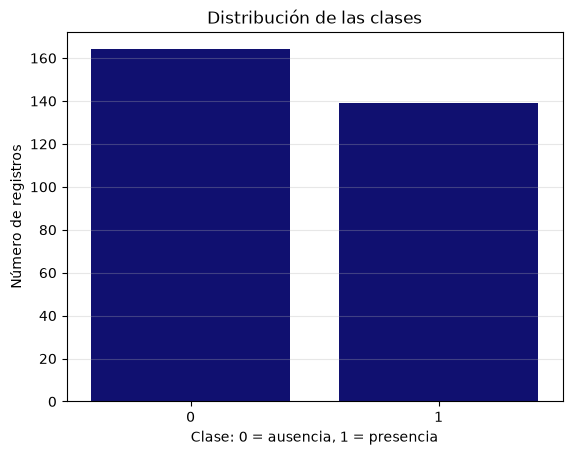

In [10]:
sns.countplot(data=df2, x="num", color="navy")

plt.xlabel("Clase: 0 = ausencia, 1 = presencia")
plt.ylabel("Número de registros")
plt.title("Distribución de las clases")
plt.grid(axis="y", alpha=0.3)
plt.show()

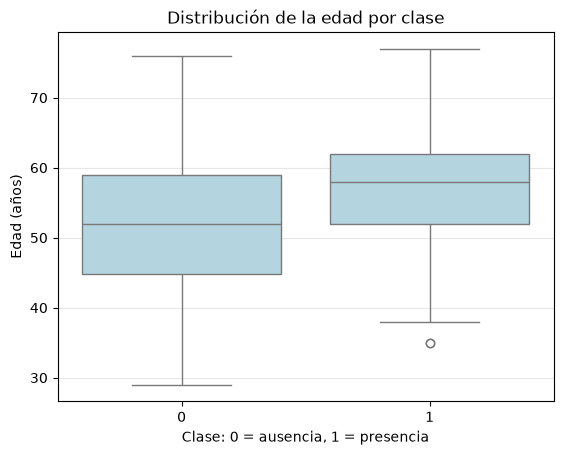

In [11]:
sns.boxplot(data=df2, x="num", y="age", color="lightblue")

plt.xlabel("Clase: 0 = ausencia, 1 = presencia")
plt.ylabel("Edad (años)")
plt.title("Distribución de la edad por clase")
plt.grid(axis="y", alpha=0.3)
plt.show()

#### Separación de los datos de entrenamiento y prueba

Usaremos el 80 % para entrenar y el 20 % para evaluar.

La variable num es la respuesta que queremos predecir, por lo que no debe incluirse entre los predictores.

In [12]:
x = df2.drop(["num"], axis=1)
y = df2.num

X_train, X_test, Y_train, Y_test = train_test_split(
    x, y,
    train_size=0.8,
    random_state=42,
    stratify=y
)

print("Entrenamiento:", X_train.shape)
print("Prueba:", X_test.shape)

Entrenamiento: (242, 13)
Prueba: (61, 13)


#### Tratamiento de valores faltantes

Sustituiremos los valores faltantes por la moda: el valor más frecuente de cada columna.

Calcularemos las modas únicamente con los datos de entrenamiento y utilizaremos esos mismos valores en prueba.

In [13]:
modas = X_train.mode().iloc[0]

X_train = X_train.fillna(modas)
X_test = X_test.fillna(modas)

X_train.isnull().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
dtype: int64

#### Conversión de categorías en columnas numéricas

Algunas columnas usan números para representar categorías.

Crearemos columnas indicadoras con valores 0 y 1 para que el modelo no interprete esos códigos como cantidades.

In [14]:
categoricas = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]

X_train = pd.get_dummies(
    X_train, columns=categoricas, dtype=int
)

X_test = pd.get_dummies(
    X_test, columns=categoricas, dtype=int
)

X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

X_train.head()

,age,trestbps,chol,thalach,oldpeak,sex_0,sex_1,cp_1,cp_2,cp_3,...,slope_1,slope_2,slope_3,ca_0.0,ca_1.0,ca_2.0,ca_3.0,thal_3.0,thal_6.0,thal_7.0
180,48,124,274,166,0.5,0,1,0,0,0,...,0,1,0,1,0,0,0,0,0,1
208,55,130,262,155,0.0,0,1,0,1,0,...,1,0,0,1,0,0,0,1,0,0
167,54,132,288,159,0.0,1,0,0,1,0,...,1,0,0,0,1,0,0,1,0,0
105,54,108,309,156,0.0,0,1,0,1,0,...,1,0,0,1,0,0,0,0,0,1
297,57,140,241,123,0.2,1,0,0,0,0,...,0,1,0,1,0,0,0,0,0,1


#### Escalamiento de los datos

Las variables tienen escalas diferentes: por ejemplo, edad y colesterol.

El escalamiento las coloca en una escala comparable para facilitar el entrenamiento.

In [15]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

#### Construcción y entrenamiento del modelo de regresión logística

El modelo aprenderá a relacionar las características con las clases 0 y 1.

In [16]:
model = LogisticRegression(max_iter=1000)

model.fit(X_train_scaled, Y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

#### Predicción con los datos de prueba

Utilizaremos el modelo entrenado para predecir las clases de los datos de prueba.

In [17]:
pred = model.predict(X_test_scaled)

#### Comparación de las clases reales y predichas

In [18]:
comparacion = pd.DataFrame({
    "Clase real": Y_test,
    "Clase predicha": pred
})

comparacion.head(10)

,Clase real,Clase predicha
219,0,0
271,0,1
89,0,0
101,0,0
67,0,0
244,0,0
185,0,0
233,0,0
168,1,1
197,0,0


#### Evaluación del modelo: exactitud

La exactitud es la proporción de predicciones correctas.

Por ejemplo, una exactitud de 80 % significa que el modelo acertó en 80 de cada 100 observaciones evaluadas.

In [19]:
acc = np.mean(pred == Y_test)

print(f"Exactitud de prueba: {acc:.2%}")

Exactitud de prueba: 85.25%


#### Evaluación del modelo: matriz de confusión

La matriz muestra los aciertos y los errores para cada clase.

- Las filas representan las clases reales.
- Las columnas representan las clases predichas.
- La diagonal principal contiene las predicciones correctas.

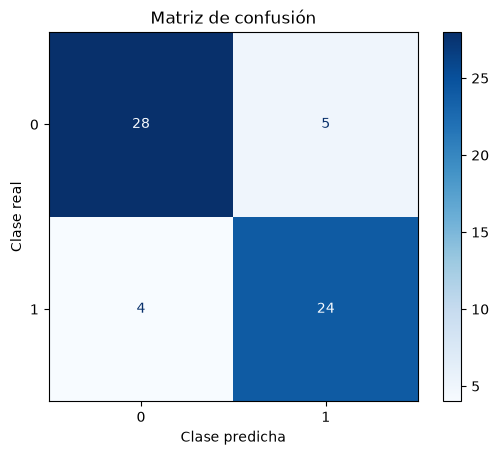

In [20]:
cm = confusion_matrix(Y_test, pred, labels=model.classes_)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=model.classes_
).plot(cmap="Blues")

plt.xlabel("Clase predicha")
plt.ylabel("Clase real")
plt.title("Matriz de confusión")
plt.show()